In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [46]:
# 1. Зареждане на Excel файла
file_path = 'data/data.xlsx'
df = pd.read_excel(file_path)

print(f"Общ брой записи в таблицата: {len(df)}")
print(f"Уникални училища: {df['Училище'].nunique()}")
print(f"Налични години: {df['Година'].unique()}")

Общ брой записи в таблицата: 320
Уникални училища: 40
Налични години: <StringArray>
['2025-2026', '2024-2025', '2023-2024', '2022-2023', '2021-2022', '2020-2021',
 '2019-2020', '2018-2019']
Length: 8, dtype: str


In [47]:
# 2. Обща статистика за целия град (всички училища)
print("=== СТАТИСТИКА ЗА ЦЕЛИЯ ГРАД (Всички училища) ===")
city_stats = df[['БЕЛ', 'МАТ']].agg(['mean', 'median', 'std', 'min', 'max'])
display(city_stats.round(2))
print("\n" + "="*50 + "\n")

=== СТАТИСТИКА ЗА ЦЕЛИЯ ГРАД (Всички училища) ===


,БЕЛ,МАТ
mean,60.99,45.51
median,64.18,44.88
std,16.60,17.96
min,7.58,8.82
max,93.22,96.95


In [48]:
# 3. Намиране на топ 15 училища въз основа на средния резултат (БЕЛ + МАТ) за целия период
school_avg = df.groupby('Училище')[['БЕЛ', 'МАТ']].mean().mean(axis=1).sort_values(ascending=False)
top_15_schools = school_avg.head(15).index.tolist()

print("\n--- ТОП 15 УЧИЛИЩА ВЪВ ВАРНА ---")
for i, school in enumerate(top_15_schools, 1):
    print(f"{i}. {school}")


--- ТОП 15 УЧИЛИЩА ВЪВ ВАРНА ---
1. МГ "Д-р Петър Берон"
2. ОУ "П. Р. Славейков"
3. ОУ "Св. Св. Кирил и Методий"
4. VII ОУ "Найден Геров"
5. ОУ "Захари Стоянов"
6. СУ "Ал. С. Пушкин"
7. СУ "Св. Климент Охридски"
8. ОУ "Г. С. Раковски"
9. ЧОУ "Малкият принц"
10. СУ "Гео Милев"
11. СУХНИ "Константин Преславски"
12. III ОУ "Ангел Кънчев"
13. ОУ "Черноризец Храбър"
14. ЧСИ "Мечтатели"
15. ОУ "Васил Друмев"


In [49]:
# 3. Филтриране на основния DataFrame само за тези топ 15 училища
df_top15 = df[df['Училище'].isin(top_15_schools)]
print(f"\nФилтриран датасет за топ 15 училища брой редове: {len(df_top15)}")


Филтриран датасет за топ 15 училища брой редове: 120


In [50]:
# 3. Изчисляване на основни статистики за Топ 15 училищата
print("\n=== СТАТИСТИКА САМО ЗА ТОП 15 УЧИЛИЩА ===")
top15_stats = df_top15[['БЕЛ', 'МАТ']].agg(['mean', 'median', 'std', 'min', 'max'])
display(top15_stats.round(2))
print("\n" + "="*50 + "\n")


=== СТАТИСТИКА САМО ЗА ТОП 15 УЧИЛИЩА ===


,БЕЛ,МАТ
mean,74.57,62.13
median,74.37,61.24
std,6.32,12.78
min,59.77,28.86
max,93.22,96.95


<Figure size 1400x700 with 0 Axes>

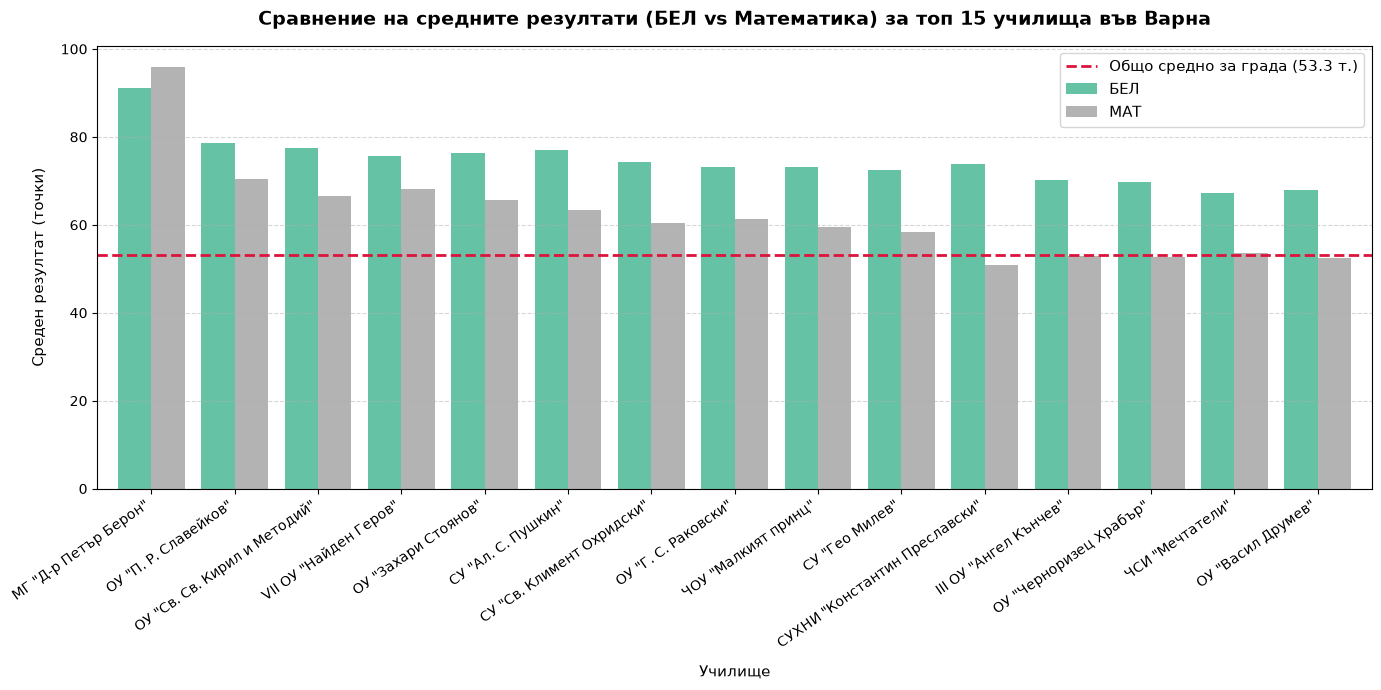

In [52]:
# Извличаме средните стойности директно от таблицата за референтната линия
city_avg_bel = city_stats.loc['mean', 'БЕЛ']
city_avg_mat = city_stats.loc['mean', 'МАТ']
overall_city_mean = (city_avg_bel + city_avg_mat) / 2

# Подготовка на данните за графиката
top_15_barplot_data = df_top15.groupby('Училище')[['БЕЛ', 'МАТ']].mean().loc[top_15_schools]

plt.figure(figsize=(14, 7))
ax = top_15_barplot_data.plot(kind='bar', figsize=(14, 7), colormap='Set2', width=0.8)

# Добавяне на червена референтна линия за общото средно ниво за града
plt.axhline(y=overall_city_mean, color='crimson', linestyle='--', linewidth=2, 
            label=f'Общо средно за града ({overall_city_mean:.1f} т.)')

# Настройки на графиката
plt.title('Сравнение на средните резултати (БЕЛ vs Математика) за топ 15 училища във Варна', fontsize=14, pad=15, fontweight='bold')
plt.xlabel('Училище', fontsize=11, labelpad=10)
plt.ylabel('Среден резултат (точки)', fontsize=11, labelpad=10)

plt.xticks(rotation=35, ha='right', fontsize=10)

plt.legend(fontsize=11, frameon=True)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
